<a href="https://colab.research.google.com/github/vianachagasaanabeatriz/Informatica-aplicada-a-logistica-/blob/main/PROVA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install pandas

In [5]:
import pandas as pd

# Carregar o dataset com codificação apropriada para português
df = pd.read_csv('/content/nupcialidade.csv', encoding='latin-1')
display(df.head())

,,,ano;nome_ra;casamentos;pop_15mais;taxa_nupcialidade;id_media_homem;id_media_mulher
2013;Estado São Paulo;280.336;33512491;8,4;32,7;29,9.0
2013;RA Araçatuba;4.960;607854;8,2;32,8;30,1.0
2013;RA Barretos;3.028;342106;8,9;32,2;29,4.0
2013;RA Bauru;7.491;858009;8,7;32,6;29,9.0
2013;RA Campinas;44.199;5171430;8,5;32,3;29,6.0


Coeficiente linear (Intercepto): -3.6951
Coeficiente angular (Inclinação): 1.0284
R² (Coeficiente de determinação): 0.9384
Erro Quadrático Médio (MSE): 0.1361


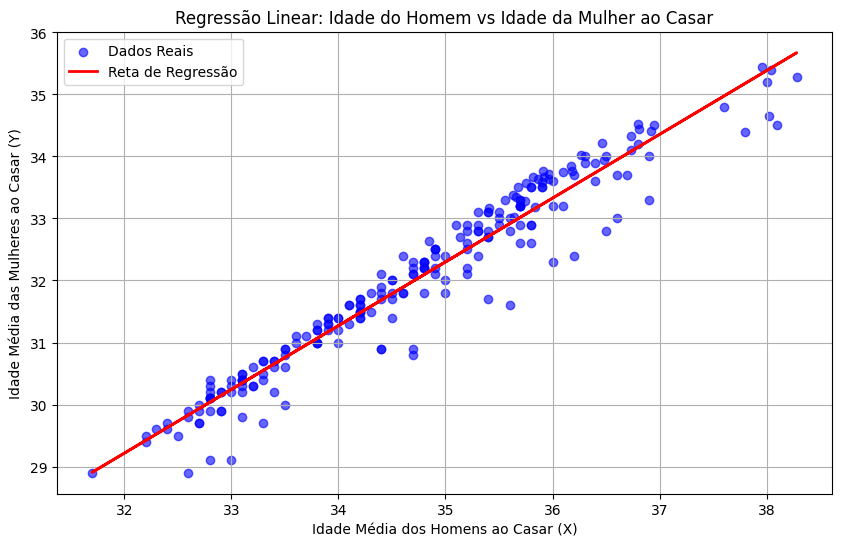

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# 1. Carregar os dados corretamente usando sep=';'
df = pd.read_csv('/content/nupcialidade.csv', encoding='latin-1', sep=';')

# 2. Limpar os dados das colunas de idade (garantindo que sejam numéricos)
# Substitui vírgulas por pontos se houver e converte para float
df['id_media_homem'] = df['id_media_homem'].astype(str).str.replace(',', '.').astype(float)
df['id_media_mulher'] = df['id_media_mulher'].astype(str).str.replace(',', '.').astype(float)

# Remover possíveis valores nulos resultantes da conversão
df = df.dropna(subset=['id_media_homem', 'id_media_mulher'])

# 3. Definir variáveis dependente (y) e independente (x)
X = df[['id_media_homem']]
y = df['id_media_mulher']

# 4. Criar e treinar o modelo de regressão linear
modelo = LinearRegression()
modelo.fit(X, y)

# 5. Fazer predições
y_pred = modelo.predict(X)

# 6. Exibir os resultados e métricas
print(f"Coeficiente linear (Intercepto): {modelo.intercept_:.4f}")
print(f"Coeficiente angular (Inclinação): {modelo.coef_[0]:.4f}")
print(f"R² (Coeficiente de determinação): {r2_score(y, y_pred):.4f}")
print(f"Erro Quadrático Médio (MSE): {mean_squared_error(y, y_pred):.4f}")

# 7. Plotar os dados e a reta de regressão
plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='blue', alpha=0.6, label='Dados Reais')
plt.plot(X, y_pred, color='red', linewidth=2, label='Reta de Regressão')
plt.title('Regressão Linear: Idade do Homem vs Idade da Mulher ao Casar')
plt.xlabel('Idade Média dos Homens ao Casar (X)')
plt.ylabel('Idade Média das Mulheres ao Casar (Y)')
plt.legend()
plt.grid(True)
plt.show()

### Resultados Obtidos do Modelo de Regressão Linear

* **Equação da Reta:**
  $$\hat{Y} = 1.0284 \cdot X - 3.6951$$
  *(Onde **$X$** é a idade média dos homens ao casar e **$Y$** é a estimativa da idade média das mulheres ao casar)*

* **Fator de Determinação ($R^2$):**
  $$R^2 = 0.9384$$
  *(Ou seja, aproximadamente **93,84%** da variabilidade da idade média das mulheres ao casar é explicada pela idade média dos homens ao casar neste modelo)*

<>:9: SyntaxWarning: invalid escape sequence '\h'
<>:9: SyntaxWarning: invalid escape sequence '\c'
<>:9: SyntaxWarning: invalid escape sequence '\h'
<>:9: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_4207/1680331850.py:9: SyntaxWarning: invalid escape sequence '\h'
  texto_anotacao = f'$\hat{{Y}} = {modelo.coef_[0]:.4f} \cdot X {modelo.intercept_:.4f}$\n$R^2 = {r2_score(y, y_pred):.4f}$'
/tmp/ipykernel_4207/1680331850.py:9: SyntaxWarning: invalid escape sequence '\c'
  texto_anotacao = f'$\hat{{Y}} = {modelo.coef_[0]:.4f} \cdot X {modelo.intercept_:.4f}$\n$R^2 = {r2_score(y, y_pred):.4f}$'


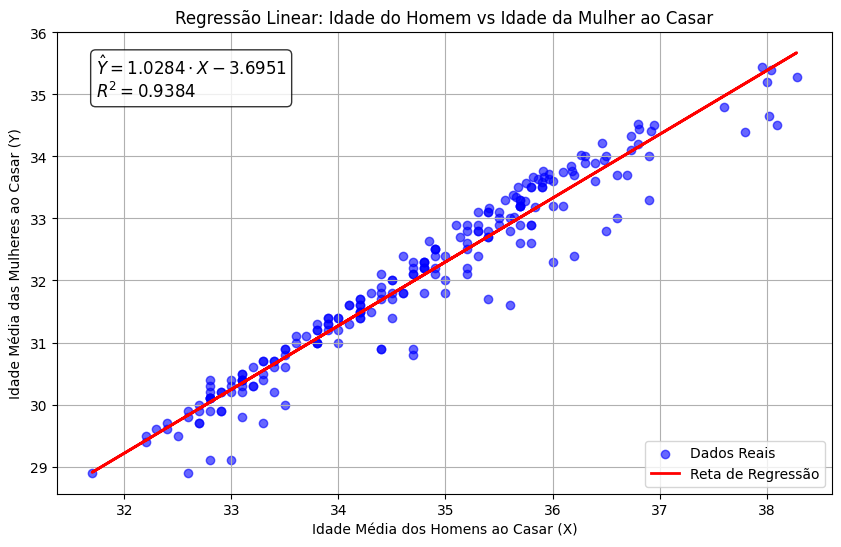

In [7]:
import matplotlib.pyplot as plt

# Criar o gráfico de dispersão com as anotações
plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='blue', alpha=0.6, label='Dados Reais')
plt.plot(X, y_pred, color='red', linewidth=2, label='Reta de Regressão')

# Adicionar a equação da reta e o R² como texto dentro do gráfico
texto_anotacao = f'$\hat{{Y}} = {modelo.coef_[0]:.4f} \cdot X {modelo.intercept_:.4f}$\n$R^2 = {r2_score(y, y_pred):.4f}$'
plt.text(0.05, 0.95, texto_anotacao, transform=plt.gca().transAxes, fontsize=12,
         verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.title('Regressão Linear: Idade do Homem vs Idade da Mulher ao Casar')
plt.xlabel('Idade Média dos Homens ao Casar (X)')
plt.ylabel('Idade Média das Mulheres ao Casar (Y)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()